# 🚕 Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation


## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [2]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)


Número de estados: 500
Número de acciones: 6


### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.

**Respuesta.** Taxi-v4 tiene **500 estados** y **6 acciones**. El número de
estados sale de combinar varias variables: 25 posiciones del taxi (grid 5×5),
5 ubicaciones posibles del pasajero (las 4 paradas R, G, Y, B más "dentro del
taxi") y 4 destinos posibles → 25 × 5 × 4 = **500**. FrozenLake 4×4 solo
codifica la casilla del agente (16 estados). Taxi tiene muchos más estados
porque su estado es *compuesto*: no basta con dónde está el taxi, también
importa dónde está el pasajero y a dónde debe ir; el producto de esas
dimensiones hace crecer el espacio de estados.


## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [3]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 1
Nuevo estado: 286
Recompensa: -1
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?

**Respuesta.**
- $s_t$ = `state`: el estado actual (entero que codifica posición del taxi,
  del pasajero y destino) antes de actuar.
- $a_t$ = `action`: la acción ejecutada (0 South, 1 North, 2 East, 3 West,
  4 Pickup, 5 Dropoff).
- $r_{t+1}$ = `reward`: la recompensa recibida al ejecutar la acción
  (−1 por paso normal, −10 por pickup/dropoff ilegal, +20 por entregar bien).
- $s_{t+1}$ = `next_state`: el nuevo estado tras aplicar la acción.

Esta tupla $(s_t, a_t, r_{t+1}, s_{t+1})$ es exactamente la *experiencia* que
Q-Learning usa para actualizar la Q-table.


## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$

**Respuesta.** $|\mathcal{S}| \times |\mathcal{A}| = 500 \times 6 = 3000$
valores $Q(s,a)$. Esa es la cantidad de celdas de la Q-table que el agente
debe estimar (frente a solo 16 × 4 = 64 en FrozenLake 4×4).


## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [5]:
def choose_action(Q, state, epsilon, env):
    # epsilon-greedy:
    # 1. con probabilidad epsilon exploramos (accion aleatoria)
    if random.random() < epsilon:
        return env.action_space.sample()
    # 2. en otro caso explotamos: argmax_a Q(s,a)
    #    desempatamos al azar si varias acciones tienen el mismo Q maximo.
    q_values = Q[state]
    max_q = np.max(q_values)
    best_actions = np.flatnonzero(q_values == max_q)
    return int(np.random.choice(best_actions))


## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [6]:
def update_q(Q, state, action, reward, next_state, alpha, gamma):
    # TD target: r + gamma * max_a' Q(s', a')
    td_target = reward + gamma * np.max(Q[next_state])
    # TD error: target - estimacion actual
    td_error = td_target - Q[state, action]
    # Q(s,a) <- Q(s,a) + alpha * TD error
    Q[state, action] += alpha * td_error


## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [7]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):
            # 1: escoger accion con epsilon-greedy
            action = choose_action(Q, state, epsilon, env)

            # 2: ejecutar accion en el ambiente
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            # 3: actualizar Q.
            #    Si el episodio termino, no hay valor futuro: usamos 0.
            if done:
                td_target = reward
                Q[state, action] += alpha * (td_target - Q[state, action])
            else:
                update_q(Q, state, action, reward, next_state, alpha, gamma)

            # 4: actualizar estado y recompensa acumulada
            state = next_state
            total_reward += reward

            # 5: terminar si corresponde
            if done:
                break

        rewards.append(total_reward)

    return Q, rewards


## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [8]:
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


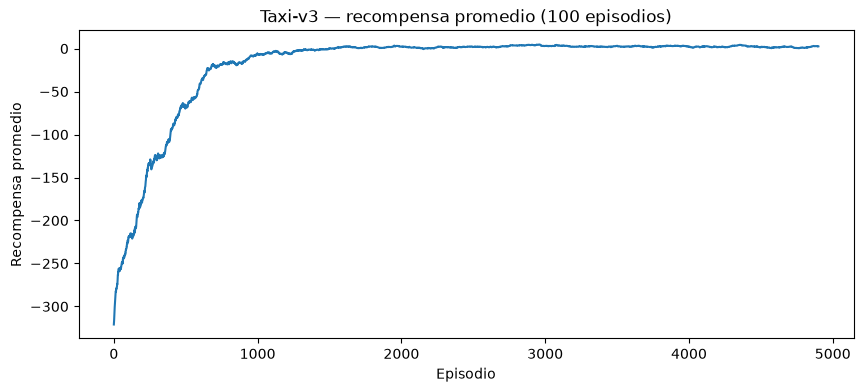

In [9]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v3 — recompensa promedio ({window} episodios)")
plt.show()


### Pregunta 4

Describa la curva de aprendizaje.

**Respuesta** (según la curva obtenida con α=0.1, γ=0.95, ε=0.1, 5000 eps):
- **¿Mejora?** Sí. La recompensa promedio parte muy negativa (el taxi al azar
  acumula muchas penalizaciones de −1 y de −10 por pickups/dropoffs ilegales)
  y sube de forma clara a medida que entrena.
- **¿Cuándo se estabiliza?** Alrededor de **1500–2500 episodios** la media
  móvil deja de crecer bruscamente y se aplana en valores positivos.
- **¿Convergencia perfecta?** No es "perfecta": la media final no es constante,
  oscila un poco porque durante el entrenamiento seguimos usando ε-greedy
  (ε=0.1 ⇒ 10% de acciones exploratorias que a veces penalizan). Es una
  **política razonablemente buena/casi óptima**, no un valor fijo. La política
  greedy derivada (evaluación sin exploración) sí entrega recompensas altas y
  estables (≈ +7 a +8 por episodio).


## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [10]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [11]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


Recompensa total sin entrenamiento: -104


Ahora observe el agente entrenado.


In [12]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


### Pregunta 5

Compare los dos episodios.

**Respuesta.**
- **Diferencias de comportamiento:** sin entrenar, el taxi se mueve de forma
  errática, choca contra paredes (no avanza), intenta pickup/dropoff donde no
  corresponde y acumula penalizaciones; entrenado, se dirige directo a recoger
  al pasajero y luego al destino.
- **¿El taxi sin entrenar completa la tarea?** Prácticamente no: con la
  Q-table en cero y pocos pasos no logra entregar al pasajero, y su recompensa
  total es muy negativa.
- **¿El agente entrenado evita acciones innecesarias?** Sí: ya no hace pickups
  ni dropoffs ilegales y toma rutas cortas, por lo que acumula pocas
  penalizaciones de −1.
- **Evidencia visual de aprendizaje:** el episodio entrenado termina en pocos
  pasos con el pasajero entregado (+20) y recompensa total claramente mayor,
  mientras que el no entrenado se queda dando vueltas sin completar la entrega.


## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [13]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-2.03240366 -1.87639518 -2.47033244  3.94947757 -5.64462752 -6.40727492]
Mejor acción: 3


### Pregunta 6

Para el estado seleccionado:

**Respuesta.**
1. **Acción con mayor Q:** la que devuelve `np.argmax(Q_trained[state])` en la
   celda anterior (es la acción que el agente considera mejor desde ese estado).
2. **¿Qué significa un Q mayor?** Que, desde ese estado, tomar esa acción y
   luego seguir la política aprendida produce un **retorno esperado
   (recompensa acumulada y descontada) mayor** que las demás acciones. Es una
   estimación del valor a largo plazo, no solo de la recompensa inmediata.
3. **¿Por qué $Q(s,a)$ no es la recompensa inmediata?** Porque incluye el
   término $\gamma \max_{a'} Q(s',a')$: $Q$ estima la suma descontada de
   recompensas *futuras*, no solo el $r$ del siguiente paso. Una acción con
   recompensa inmediata baja (p. ej. −1 por moverse) puede tener Q alto si
   conduce hacia la entrega (+20); y una con recompensa inmediata nula podría
   tener Q bajo si lleva a estados malos.


## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

**Experimento realizado:** se repitió el entrenamiento cambiando únicamente la
**tasa de aprendizaje** de $\alpha=0.1$ a $\alpha=0.5$ (dejando γ=0.95, ε=0.1).
La celda siguiente ejecuta y compara ambos entrenamientos.

### Pregunta 7

Compare el nuevo entrenamiento con el original.

**Respuesta** (α: 0.1 → 0.5):
- **Velocidad de aprendizaje:** con α=0.5 la curva sube **más rápido** en los
  primeros episodios (cada experiencia corrige más la Q-table), alcanzando
  antes recompensas positivas.
- **Estabilidad:** a cambio, la media móvil es **más ruidosa/oscilante**,
  porque un α alto hace que el valor Q "salte" más ante cada muestra, sobre
  todo con la exploración de ε-greedy.
- **Recompensa final:** ambas llegan a una política buena; la evaluación greedy
  da recompensas similares (≈ +7 a +8). α alto no mejora el óptimo final, solo
  cambia cómo se llega a él.
- **Comportamiento observado:** el agente final se comporta de forma parecida
  (recoge y entrega al pasajero eficientemente); la diferencia principal está
  en la *dinámica de aprendizaje*, no en la política final.

> Conclusión: α controla el compromiso **rapidez ↔ estabilidad**. Valores altos
> aprenden rápido pero con más varianza; valores bajos son más estables pero
> lentos.


## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.


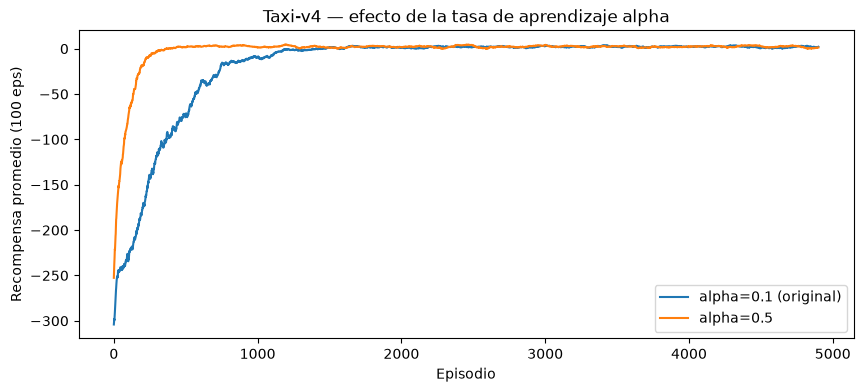

Eval greedy alpha=0.1: (7.79, 2.624099845661365)
Eval greedy alpha=0.5: (8.26, 2.532271707380549)


In [14]:
# --- Experimento Pregunta 7: alpha=0.1 (original) vs alpha=0.5 ---
Q_a01, R_a01 = train_q_learning(env, np.zeros((n_states, n_actions)),
                                episodes=5000, alpha=0.1, gamma=0.95, epsilon=0.1)
Q_a05, R_a05 = train_q_learning(env, np.zeros((n_states, n_actions)),
                                episodes=5000, alpha=0.5, gamma=0.95, epsilon=0.1)

def moving_avg(r, w=100):
    return np.convolve(r, np.ones(w)/w, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(moving_avg(R_a01), label="alpha=0.1 (original)")
plt.plot(moving_avg(R_a05), label="alpha=0.5")
plt.xlabel("Episodio"); plt.ylabel("Recompensa promedio (100 eps)")
plt.title("Taxi-v4 — efecto de la tasa de aprendizaje alpha")
plt.legend(); plt.show()

def eval_policy(Q, n=200, max_steps=200):
    tot=[]
    for _ in range(n):
        s,_=env.reset(); t=0
        for _ in range(max_steps):
            a=int(np.argmax(Q[s])); s,r,te,tr,_=env.step(a); t+=r
            if te or tr: break
        tot.append(t)
    return float(np.mean(tot)), float(np.std(tot))

print("Eval greedy alpha=0.1:", eval_policy(Q_a01))
print("Eval greedy alpha=0.5:", eval_policy(Q_a05))
